<a href="https://colab.research.google.com/github/DiShaYa/genetic-algorithm/blob/main/%D0%93%D0%B5%D0%BD_%D0%B0%D0%BB%D0%B3%D0%BE%D1%80%D0%B8%D1%82%D0%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 10 родителей с помощью алгоритма, одна эпоха
""" Описать функционирование одной эпохи генетического алгоритма на
примере произвольной задачи (не менее пяти признаков закодировать
случайным образом, начальная популяция содержит не менее 10
особей). Использовать следующие параметры генетического
алгоритма:
1) фитнесс-функция – сумма всех бит особи, деленная на
количество бит в особи;
2) метод отбора – пропорциональный с
использованием принципа элитизма;
3) оператор скрещивания – двухточечный кроссовер;
4) оператор мутации – инверсия."""
!pip install graycode

In [ ]:
#Набор признаков
import random
import graycode
characteristics = []
tens = []
Gray=[]

def binary_to_gray(binary):    # Преобразование двоичного числа в Код Грея
    binary = int(binary, 2)
    gray = binary ^ (binary >> 1)
    return f"{gray:04b}"

for i in range(5): #формирование признаков
  a=random.randint(1, 15)
  char = f"{a:04b}"
  tens.append(a)
  Gray.append(binary_to_gray(char))
  characteristics.append(char)
print("Признаки:")
print("Десятичная система:      ",tens)
print("Двоичная система:        ",characteristics)
print("Преобразования кода Грея:",Gray)

#Формирование популяции
first=[]
second=[]
subset1 = characteristics[0:2]
subset2 = characteristics[2:5]
for i in range(10):
  random_first = random.choice(subset1)
  first.append(random_first)
  random_second = random.choice(subset2)
  second.append(random_second)
popul = [k + l for k, l in zip(first, second)]
print("Популяция:", popul)
#1) оценка приспособленнности особей - фитнесс-функция: сумма всех бит особи, деленная на количество бит в особи;
fitness= []
def count_bits(binary): # Подсчёт количества бит в двоичном числе
    return binary.count("1")

print(' Фитнес Функция = Сумма бит/ кол-во бит особи')
for i in popul:
  fit = count_bits(i)
  fit = fit/8;
  fitness.append(fit)
print("Фитнес функция =",fitness)
sr=0;
sr = sum(fitness)/10;
print("Среднее значение фитнес функции",sr)

print(' Приспособ функции = зн. фитнес функции/ среднее зн')
prisposob = []
pris=0
for t in fitness:
  pris = t/sr
  prisposob.append(pris)
print("Приспособленность особей:", prisposob)


Признаки:
Десятичная система:       [12, 1, 13, 15, 2]
Двоичная система:         ['1100', '0001', '1101', '1111', '0010']
Преобразования кода Грея: ['1010', '0001', '1011', '1000', '0011']
Популяция: ['00011101', '11000010', '11000010', '11001101', '11001101', '00010010', '11000010', '00010010', '00011111', '11001101']
 Фитнес Функция = Сумма бит/ кол-во бит особи
Фитнес функция = [0.5, 0.375, 0.375, 0.625, 0.625, 0.25, 0.375, 0.25, 0.625, 0.625]
Среднее значение фитнес функции 0.4625
 Приспособ функции = зн. фитнес функции/ среднее зн
Приспособленность особей: [1.081081081081081, 0.8108108108108107, 0.8108108108108107, 1.3513513513513513, 1.3513513513513513, 0.5405405405405405, 0.8108108108108107, 0.5405405405405405, 1.3513513513513513, 1.3513513513513513]


Вероятности PS(i) = приспособ. особи/ сумарную приспособ (10)
Суммарная приспособленость: 9.999999999999998
Вероятности PS(i) [0.10810810810810811, 0.08108108108108109, 0.08108108108108109, 0.13513513513513514, 0.13513513513513514, 0.05405405405405406, 0.08108108108108109, 0.05405405405405406, 0.13513513513513514, 0.13513513513513514]
Выбрана элитная пара:
  Первый 'элитный' партнер: 11001101 с приспособленностью 1.3513513513513513
  Второй 'элитный' партнер: 11001101 с приспособленностью 1.3513513513513513


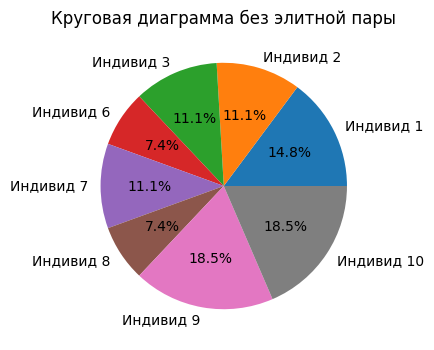


партнеры с первой стороны:   ['11001101', '00010010', '11000010', '11000010', '11001101']
партнеры  со второй стороны: ['11001101', '11001101', '00010010', '00011111', '00011111']


In [ ]:
#2) Отбор - пропорциональный с использованием принципа элитизма;
#каждой особи назначает вероятность Ps(i), равную отношению ее приспособленности к суммарной приспособленности популяции,
import matplotlib.pyplot as plt
sumpris = sum(prisposob)
#Должна равняться 10
print('Вероятности PS(i) = приспособ. особи/ сумарную приспособ (10)')
print('Суммарная приспособленость:',sumpris)
pss = []
for y in prisposob:
    ps= y/sumpris
    pss.append(ps)
print("Вероятности PS(i)", pss)

def select_new_population(popul, prisposob, pss, total_population_size=10, elite_count=2):
    #  Создаем список кортежей (особь, приспособленность, вероятность)
    pop_info = list(zip(popul, prisposob, pss))
    #  Сортируем по убыванию приспособленности (самые приспособленные – впереди)
    sorted_pop = sorted(pop_info, key=lambda x: x[1], reverse=True)
    # Выбираем элитную пару (топ-2) - как принцип элитизма
    elite = sorted_pop[:elite_count]
    elite_first = elite[0][0]
    elite_second = elite[1][0]
    print("Выбрана элитная пара:")
    print(f"  Первый 'элитный' партнер: {elite[0][0]} с приспособленностью {elite[0][1]}")
    print(f"  Второй 'элитный' партнер: {elite[1][0]} с приспособленностью {elite[1][1]}")


    # Подготавливаем оставшихся кандидатов для пропорционального отбора
    remaining = sorted_pop[elite_count:]
    remaining_pop = [item[0] for item in remaining]
    remaining_pss = [item[2] for item in remaining]

    # Вычисляем, сколько особей нужно выбрать пропорционально:
    selection_count = total_population_size - elite_count
    # Пропорциональный отбор
    selected = random.choices(remaining_pop, weights=remaining_pss, k=selection_count)

    # Формируем два списка для дальнейшего скрещивания
    partnersones = [elite_first]
    partnerstwos = [elite_second]
    for i, individual in enumerate(selected):
        if i % 2 == 0:
            partnersones.append(individual)
        else:
            partnerstwos.append(individual)
    return partnersones, partnerstwos

partnersones, partnerstwos = select_new_population(popul, prisposob, pss)

indexed = list(enumerate(prisposob))

#диаграмма
sorted_by_value = sorted(indexed, key=lambda x: x[1], reverse=True)
elite_indices = [sorted_by_value[0][0], sorted_by_value[1][0]]
filtered = [v for i, v in enumerate(prisposob) if i not in elite_indices]
labels = [f'Индивид {i+1}' for i in range(len(prisposob)) if i not in elite_indices]
colors = plt.cm.tab10.colors  # 10 разных цветов
plt.figure(figsize=(4,4))
plt.pie(filtered, labels=labels, colors=colors[:8], autopct='%1.1f%%')
plt.title("Круговая диаграмма без элитной пары")
plt.show()

print("\nпартнеры с первой стороны:  ", partnersones)
print("партнеры  со второй стороны:", partnerstwos)



In [ ]:
# 3) оператор скрещивания – двухточечный кроссовер;
def crossover(partnersones, partnerstwos):
    """
    Выполняет скрещивание (двухточечный кроссовер) для всех пар, используя одни и те же точки разрыва.
    выбираются две точки разрыва и родительские хромосомы обмениваются сегментом, который находится между двумя этими точками
    """
    # Проверка: длина генотипа должна быть одинаковой для всех особей
    length = len(partnersones[0])
    assert all(len(ind) == length for ind in partnersones + partnerstwos)

    # Выбираем точки разрыва (условия: разница >= 2, точки не равны 1 или длине генотипа)
    points = sorted(random.sample(range(2, length), 2))  # Две точки разрыва
    crossover_point1, crossover_point2 = points[0], points[1]
    print(f"Точки разрыва для всех пар: {crossover_point1}, {crossover_point2}\n")

    offspring_ones = []
    offspring_twos = []

    # Для каждой пары выполняем двухточечный кроссовер с фиксированными точками разрыва
    for idx, (parent1, parent2) in enumerate(zip(partnersones, partnerstwos)):
        parent1_display = (parent1[:crossover_point1] + "|" +
                           parent1[crossover_point1:crossover_point2] + "|" +
                           parent1[crossover_point2:])
        parent2_display = (parent2[:crossover_point1] + "|" +
                           parent2[crossover_point1:crossover_point2] + "|" +
                           parent2[crossover_point2:])

        print(f"Пара {idx+1}:")
        print(f"  Родитель 1: {parent1_display}")
        print(f"  Родитель 2: {parent2_display}")

        offspring1 = (parent1[:crossover_point1] +
                      parent2[crossover_point1:crossover_point2] +
                      parent1[crossover_point2:])
        offspring2 = (parent2[:crossover_point1] +
                      parent1[crossover_point1:crossover_point2] +
                      parent2[crossover_point2:])

        offspring1_display = (offspring1[:crossover_point1] + "|" +
                              offspring1[crossover_point1:crossover_point2] + "|" +
                              offspring1[crossover_point2:])
        offspring2_display = (offspring2[:crossover_point1] + "|" +
                              offspring2[crossover_point1:crossover_point2] + "|" +
                              offspring2[crossover_point2:])

        print(f"  Потомок 1: {offspring1_display}")
        print(f"  Потомок 2: {offspring2_display}")
        offspring_ones.append(offspring1)
        offspring_twos.append(offspring2)
    return offspring_ones, offspring_twos

offspring_ones, offspring_twos = crossover(partnersones, partnerstwos)

print("\nРезультат скрещивания:")
print("Список offspring_ones:", offspring_ones)
print("Список offspring_twos:", offspring_twos)

Точки разрыва для всех пар: 2, 5

Пара 1:
  Родитель 1: 11|001|101
  Родитель 2: 11|001|101
  Потомок 1: 11|001|101
  Потомок 2: 11|001|101
Пара 2:
  Родитель 1: 00|010|010
  Родитель 2: 11|001|101
  Потомок 1: 00|001|010
  Потомок 2: 11|010|101
Пара 3:
  Родитель 1: 11|000|010
  Родитель 2: 00|010|010
  Потомок 1: 11|010|010
  Потомок 2: 00|000|010
Пара 4:
  Родитель 1: 11|000|010
  Родитель 2: 00|011|111
  Потомок 1: 11|011|010
  Потомок 2: 00|000|111
Пара 5:
  Родитель 1: 11|001|101
  Родитель 2: 00|011|111
  Потомок 1: 11|011|101
  Потомок 2: 00|001|111

Результат скрещивания:
Список offspring_ones: ['11001101', '00001010', '11010010', '11011010', '11011101']
Список offspring_twos: ['11001101', '11010101', '00000010', '00000111', '00001111']


In [ ]:
# 4) оператор мутации – инверсия.
def force_inversion_mutation(individual):
    length = len(individual)
    # Выбираем 2 уникальных индекса из диапазона [0, length)
    start, end = sorted(random.sample(range(length), 2))
    if end - start < 2:
        end = start + 2 if start + 2 <= length else length
    segment = individual[start:end]
    segment_inverted = segment[::-1]
    mutated = individual[:start] + segment_inverted + individual[end:]

    original_marked = individual[:start] + "|" + individual[start:end] + "|" + individual[end:]
    mutated_marked = individual[:start] + "|" + segment_inverted + "|" + individual[end:]
    print(f"  Мутация для {individual} (точки: {start}, {end}):")
    print(f"    Исходная с выделением: {original_marked}")
    print(f"    После мутации:         {mutated_marked}")
    return mutated

# Объединяем потомков после скрещивания в один список
all_offspring = offspring_ones + offspring_twos
print("\nОбщее количество потомков после скрещивания:", len(all_offspring))

# Формируем группу наследников – выбираем первые 8 потомков без изменений
descendants = all_offspring[:8]

# Выбираем 3 случайных индивида для принудительной мутации
indices_for_mutation = random.sample(range(len(all_offspring)), 3)
mutated_offspring = []
print("\nПрименение оператора мутации к выбранным потомкам:")
for idx in indices_for_mutation:
    indiv = all_offspring[idx]
    mutated_indiv = force_inversion_mutation(indiv)
    mutated_offspring.append(mutated_indiv)

# Сохраняем элитную особь (наилучшая, например, первый элитный партнер)
elite_individual = partnersones[0]

# Формируем итоговую новую популяцию:

final_population = descendants + mutated_offspring

# Итоговый вывод новой популяции
print("\nФормирование новой популяции:")
for i, indiv in enumerate(final_population, start=1):
    print(f"Особь 2.{i}: {indiv}")

print("\nГруппировка:")
print("Особь 2.1 – 2.7  – наследники (без мутации)")
print("Особь 2.8 – 2.10 – мутированные особи")
print("Особь 2.11      – сохраняется элитная особь (максимальная приспособленность)")


Общее количество потомков после скрещивания: 10

Применение оператора мутации к выбранным потомкам:
  Мутация для 00000010 (точки: 1, 7):
    Исходная с выделением: 0|000001|0
    После мутации:         0|100000|0
  Мутация для 11010101 (точки: 4, 6):
    Исходная с выделением: 1101|01|01
    После мутации:         1101|10|01
  Мутация для 11010010 (точки: 2, 7):
    Исходная с выделением: 11|01001|0
    После мутации:         11|10010|0

Формирование новой популяции:
Особь 2.1: 11001101
Особь 2.2: 00001010
Особь 2.3: 11010010
Особь 2.4: 11011010
Особь 2.5: 11011101
Особь 2.6: 11001101
Особь 2.7: 11010101
Особь 2.8: 00000010
Особь 2.9: 01000000
Особь 2.10: 11011001
Особь 2.11: 11100100

Группировка:
Особь 2.1 – 2.7  – наследники (без мутации)
Особь 2.8 – 2.10 – мутированные особи
Особь 2.11      – сохраняется элитная особь (максимальная приспособленность)
